In [3]:
import numpy as np
import pandas as pd
import geopandas as gpd
import movingpandas as mpd
import shapely as shp
import hvplot.pandas
import matplotlib.pyplot as plt
import h3
import folium
from movingpandas import TrajectoryCollection

In [4]:
from geopandas import GeoDataFrame, read_file
from shapely.geometry import Point, LineString, Polygon
from datetime import datetime, timedelta
from holoviews import opts, dim
from os.path import exists
from urllib.request import urlretrieve

import warnings

warnings.filterwarnings("ignore")

plot_defaults = {"linewidth": 5, "capstyle": "round", "figsize": (9, 3), "legend": True}
opts.defaults(
    opts.Overlay(active_tools=["wheel_zoom"], frame_width=300, frame_height=500)
)
hvplot_defaults = {"tiles": None, "cmap": "Viridis", "colorbar": True}

mpd.show_versions()


MovingPandas 0.21.3

SYSTEM INFO
-----------
python     : 3.13.5 (main, Jun 11 2025, 15:36:57) [Clang 17.0.0 (clang-1700.0.13.3)]
executable : /opt/homebrew/Cellar/jupyterlab/4.4.0_1/libexec/bin/python
machine    : macOS-15.2-arm64-arm-64bit-Mach-O

PROJ INFO
-----------
PROJ       : 9.5.1
PROJ data dir: /opt/homebrew/Cellar/jupyterlab/4.4.0_1/libexec/lib/python3.13/site-packages/pyproj/proj_dir/share/proj

PYTHON DEPENDENCIES
-------------------
numpy      : 2.3.5
geopandas  : 1.0.1
geopy      : 2.4.1
geoviews   : 1.14.0
holoviews  : 1.20.2
hvplot     : 0.11.2
mapclassify: 2.8.1
matplotlib : 3.10.1
pandas     : 2.2.3
pyproj     : 3.7.1
shapely    : 2.1.0
stonesoup  : 1.6


In [7]:
%%time
df = pd.read_csv("/Users/avaisman/tmp/DataMisc/Delhi/2021/2021-01-30_all.csv", index_col=0)
print(f"Finished reading {len(df)}")

Finished reading 180573
CPU times: user 180 ms, sys: 55.7 ms, total: 236 ms
Wall time: 283 ms


In [8]:
df.head()

,uid,dateTime,deviceId,lat,long,pm1_0,pm2_5,pm10
0,0db83849-cd24-477a-a9d8-e48da1c914a3,2021-01-30 00:00:01+05:30,00000000c37f0aa8,28.579370,77.228798,94.0,142.0,156.0
1,a77c4ff0-7723-418b-a02e-5653e9fa4530,2021-01-30 00:00:01+05:30,10000000dc5bb76b,28.579414,77.231705,127.0,213.0,231.0
2,f3109afa-7234-44a1-9911-b01646e33ed8,2021-01-30 00:00:04+05:30,10000000dc5bb76b,28.579414,77.231705,126.0,214.0,231.0
3,39b07547-9467-45c6-85e9-3a917ce969f3,2021-01-30 00:00:04+05:30,00000000c37f0aa8,28.579367,77.228806,94.0,145.0,157.0
4,41b70559-af34-486d-975b-9de3bd30c0f0,2021-01-30 00:00:06+05:30,10000000dc5bb76b,28.579414,77.231705,128.0,218.0,238.0


<Axes: xlabel='long', ylabel='lat'>

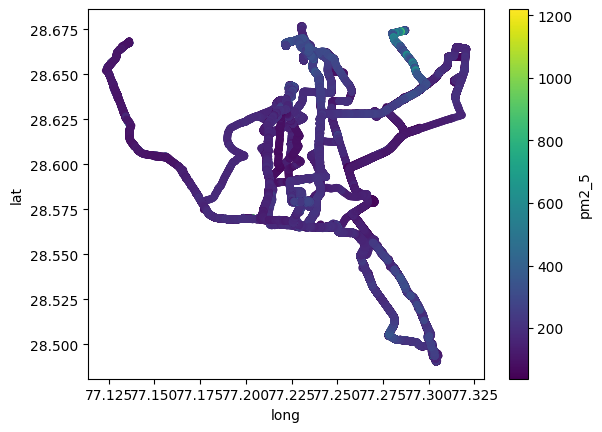

In [9]:
df.plot(c="pm2_5", x="long", y="lat", kind="scatter")

In [10]:
tc = mpd.TrajectoryCollection(df, "deviceId", t="dateTime", x="long", y="lat")
print(tc)

TrajectoryCollection with 11 trajectories


In [11]:
#Removing problematic trajectories
#We use Particulate Matter (PM) as an indicator for air pollution:

In [12]:
traj_gdf = tc.to_traj_gdf(agg={"pm2_5": "mean"})

In [13]:
traj_gdf.head()

,deviceId,start_t,end_t,geometry,length,direction,pm2_5_mean
0,00000000078e6811,2021-01-30 20:21:24,2021-01-30 21:18:39,"LINESTRING (77.29629 28.51633, 77.2962 28.5165...",15814.956415,318.600514,208.582883
1,0000000024568afd,2021-01-30 04:58:32,2021-01-30 22:23:15,"LINESTRING (77.22741 28.57927, 77.22738 28.579...",249532.107388,88.126158,175.879193
2,0000000029c36345,2021-01-30 00:43:31,2021-01-30 23:59:59,"LINESTRING (77.23292 28.57935, 77.23292 28.579...",176963.426990,95.587633,197.762287
3,0000000038861c77,2021-01-30 00:00:10,2021-01-30 23:59:54,"LINESTRING (77.23666 28.56515, 77.23665 28.565...",231838.223065,106.702579,200.204054
4,00000000812d59d2,2021-01-30 01:06:57,2021-01-30 23:53:52,"LINESTRING (77.22942 28.57948, 77.22933 28.579...",202851.356394,253.593069,166.860982


In [14]:
len(traj_gdf)

11

In [15]:
def select_by_positions(tc, positions):
    """
    Selects trayectores from a TrajectoryCollection by position  (indices).

    Args:
        tc (TrajectoryCollection): El TrajectoryCollection original.
        positions (list of int): Lista de posiciones a seleccionar.

    Returns:
        TrajectoryCollection: New TrajectoryCollection with the selected trajectories.
    """
    # Extracts selected trajectories using .trajectories
    subset = [tc.trajectories[i] for i in positions]
    
    # Crear un nuevo TrajectoryCollection
    return TrajectoryCollection(subset)

In [16]:
posiciones_deseadas = [1,5,8]  # example
tc_subset = select_by_positions(tc, posiciones_deseadas)

In [ ]:
my_trajs = tc_subset

In [ ]:
my_trajs.explore(column="deviceId", cmap="tab10", tiles="CartoDB positron")

In [19]:
my_trajs

TrajectoryCollection with 3 trajectories

In [20]:
my_traj = tc.trajectories[1]
print(my_traj)

Trajectory 0000000024568afd (2021-01-30 04:58:32 to 2021-01-30 22:23:15) | Size: 14428 | Length: 249532.1m
Bounds: (77.123329, 28.490446, 77.305397, 28.668318)
LINESTRING (77.227409 28.579273, 77.22737849999999 28.5793215, 77.22734799999998 28.57937, 77.227389


In [ ]:
my_traj.hvplot(line_width=3.0, tiles="OSM")

In [ ]:
my_traj.explore(tiles="CartoDB positron", style_kwds={"weight": 4})

In [24]:
my_traj = tc.trajectories[1]
my_traj.df

,uid,deviceId,pm1_0,pm2_5,pm10,geometry
dateTime,,,,,,
2021-01-30 04:58:32,c1c0dd83-9bff-420a-b4e5-50bc0f603d59,0000000024568afd,108.0,198.0,211.0,POINT (77.22741 28.57927)
2021-01-30 04:58:35,d8678c0b-9016-46f7-ba43-4b6ebf83a393,0000000024568afd,109.0,197.0,211.0,POINT (77.22738 28.57932)
2021-01-30 04:58:38,317f0a87-2378-4255-984b-ccfd009704b8,0000000024568afd,109.0,197.0,213.0,POINT (77.22735 28.57937)
2021-01-30 04:58:41,90ee48d7-7251-4af3-9c73-7d85810cde01,0000000024568afd,109.0,198.0,212.0,POINT (77.22739 28.57935)
2021-01-30 04:58:43,b2e3873c-5adb-44ba-bd73-b0dfe3fe22fb,0000000024568afd,111.0,198.0,213.0,POINT (77.22742 28.57933)
...,...,...,...,...,...,...
2021-01-30 22:22:55,e27f9d1a-3b45-4b01-b5ba-4d07e6b5dc72,0000000024568afd,123.0,207.0,221.0,POINT (77.23483 28.5793)
2021-01-30 22:22:58,977c9574-a4b8-426b-adca-a6bc13714ed2,0000000024568afd,122.0,203.0,221.0,POINT (77.23484 28.57928)
2021-01-30 22:23:09,d9cbdb8a-1912-4ef7-85c4-a1366d14031e,0000000024568afd,119.0,198.0,218.0,POINT (77.23479 28.57946)


In [ ]:
my_trajs.explore(tiles="CartoDB positron", style_kwds={"weight": 4}, column="speed")

<Axes: >

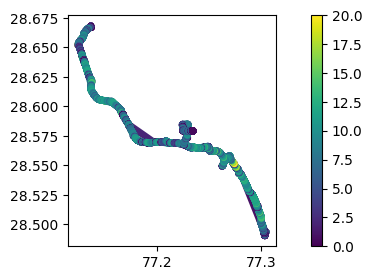

In [28]:
#Even if the Trajectory/TrajectoryCollection GeoDataFrame does not contain a speed column, we can still plot movement speed:
my_traj.plot(
    column="speed", linewidth=5, capstyle="round", figsize=(9, 3), legend=True, vmax=20
)

In [ ]:
my_traj.hvplot(
    c="speed",
    clim=(0, 20),
    line_width=7.0,
    tiles="CartoLight",
    cmap="Viridis",
    colorbar=True,
)

In [ ]:
traj_gdf.plot("pm2_5_mean", cmap="YlOrRd", linewidth=0.7, legend=True, aspect=1)

In [ ]:
#We remove problematic trajectories as much as we can:
split = mpd.ObservationGapSplitter(tc).split(gap=timedelta(minutes=10))
split

In [148]:
my_traj

Trajectory 0000000024568afd (2021-01-30 04:58:32 to 2021-01-30 22:23:15) | Size: 14428 | Length: 249532.1m
Bounds: (77.123329, 28.490446, 77.305397, 28.668318)
LINESTRING (77.227409 28.579273, 77.22737849999999 28.5793215, 77.22734799999998 28.57937, 77.227389

In [170]:
my_traj_split = mpd.ObservationGapSplitter(my_traj).split(gap=timedelta(minutes=20)) 

In [171]:
my_traj_split 

TrajectoryCollection with 5 trajectories

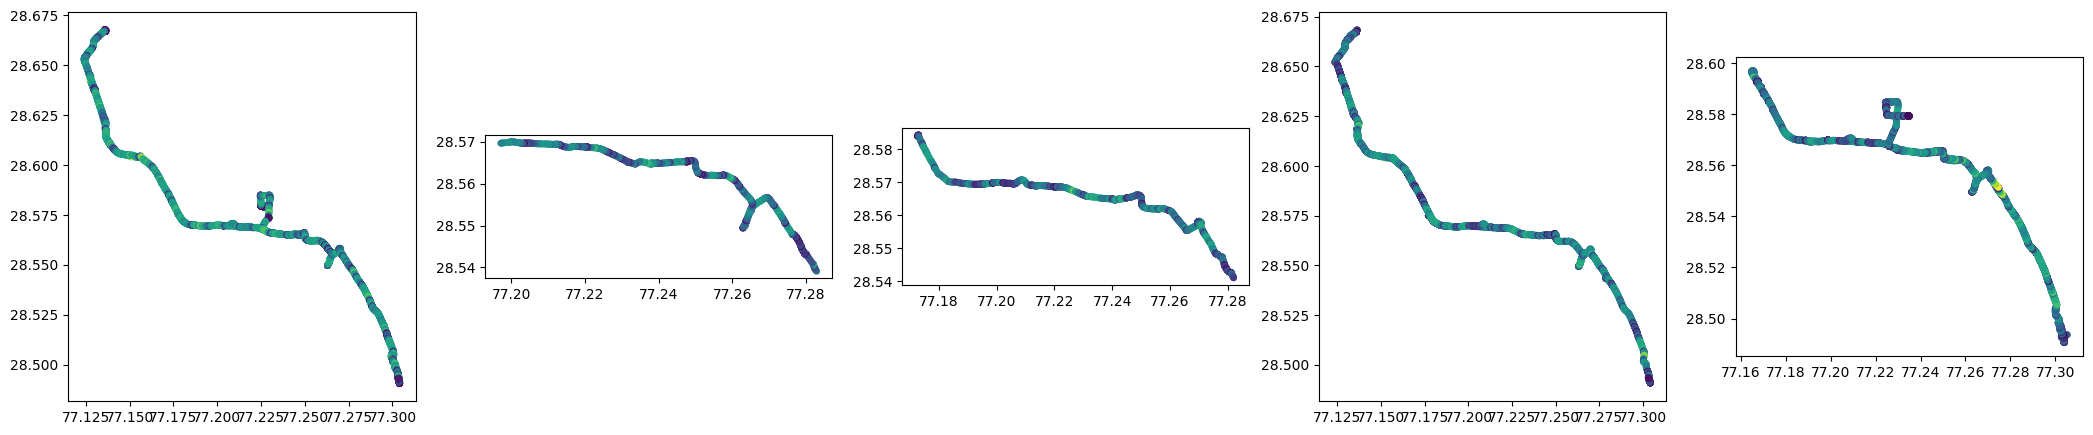

In [176]:
fig, axes = plt.subplots(nrows=1, ncols=len(my_traj_split), figsize=(26, 6))
for i, traj in enumerate(my_traj_split ):
    traj.plot(ax=axes[i], linewidth=5.0, capstyle="round", column="speed", vmax=20)

In [ ]:
my_traj_split.trajectories[1].explore(tiles="CartoDB positron", style_kwds={"weight": 4})

In [ ]:
my_traj_split.trajectories[1].explore(tiles="CartoDB positron", style_kwds={"weight": 4}, column="speed")

In [87]:
traj_gdf = split.to_traj_gdf(agg={"pm2_5": "mean", "speed": "max"})

In [88]:
#Anything over a speed of 108km/h or 30m/s seems unlikely for a bus, so let's filter these points out:
traj_gdf = traj_gdf[traj_gdf.speed_max < 108]

In [ ]:
traj_gdf["start_t"] = traj_gdf["start_t"].astype(str)
traj_gdf["end_t"] = traj_gdf["end_t"].astype(str)

In [ ]:
traj_gdf = traj_gdf.round(2)
traj_gdf.explore(
    column="pm2_5_mean",
    cmap="YlOrRd",
    tiles="CartoDB positron",
    style_kwds={"weight": 4},
)

In [50]:
#Assigning H3 cell IDs to trajectory points
#Filter by realistic speed:

point_gdf = split.to_point_gdf()
point_gdf = point_gdf[point_gdf.speed < 30]
point_gdf["x"] = point_gdf.geometry.x
point_gdf["y"] = point_gdf.geometry.y

In [51]:
point_gdf.head()

,uid,deviceId,pm1_0,pm2_5,pm10,geometry,speed,x,y
dateTime,,,,,,,,,
2021-01-30 20:21:29,28245f16-1106-4ab0-81bf-099de4e48d79,00000000078e6811_0,128.0,212.0,251.0,POINT (77.29612 28.51673),27.443267,77.296121,28.516728
2021-01-30 20:21:33,d0994c8b-208e-4bff-8afc-b091feac1162,00000000078e6811_0,128.0,213.0,254.0,POINT (77.29602 28.51699),27.443262,77.296021,28.516989
2021-01-30 20:21:38,55c47d6c-4c15-4807-8897-76cf1398ef3a,00000000078e6811_0,133.0,215.0,261.0,POINT (77.29585 28.51742),28.561704,77.295853,28.517420
2021-01-30 20:24:58,17d49dee-4b05-461a-83d3-4d95a12a02cc,00000000078e6811_0,140.0,227.0,260.0,POINT (77.28574 28.53448),28.693861,77.285744,28.534485
2021-01-30 20:25:51,738dab30-4b15-4b26-b5da-cad595527d3c,00000000078e6811_0,138.0,213.0,243.0,POINT (77.28287 28.53916),17.840033,77.282872,28.539160


In [52]:
#We can assign H3 cell IDs to each point in a trajectory:

In [53]:
res = 7
point_gdf["h3_cell"] = point_gdf.apply(
    lambda r: str(h3.latlng_to_cell(r.y, r.x, res)), axis=1
)
point_gdf.head()

,uid,deviceId,pm1_0,pm2_5,pm10,geometry,speed,x,y,h3_cell
dateTime,,,,,,,,,,
2021-01-30 20:21:29,28245f16-1106-4ab0-81bf-099de4e48d79,00000000078e6811_0,128.0,212.0,251.0,POINT (77.29612 28.51673),27.443267,77.296121,28.516728,873da1072ffffff
2021-01-30 20:21:33,d0994c8b-208e-4bff-8afc-b091feac1162,00000000078e6811_0,128.0,213.0,254.0,POINT (77.29602 28.51699),27.443262,77.296021,28.516989,873da1072ffffff
2021-01-30 20:21:38,55c47d6c-4c15-4807-8897-76cf1398ef3a,00000000078e6811_0,133.0,215.0,261.0,POINT (77.29585 28.51742),28.561704,77.295853,28.517420,873da1072ffffff
2021-01-30 20:24:58,17d49dee-4b05-461a-83d3-4d95a12a02cc,00000000078e6811_0,140.0,227.0,260.0,POINT (77.28574 28.53448),28.693861,77.285744,28.534485,873da1074ffffff
2021-01-30 20:25:51,738dab30-4b15-4b26-b5da-cad595527d3c,00000000078e6811_0,138.0,213.0,243.0,POINT (77.28287 28.53916),17.840033,77.282872,28.539160,873da1074ffffff


In [54]:
#We can use the mean of PM2.5 as a pollution measurement:

h3_df_mean = point_gdf.groupby(["h3_cell"])["pm2_5"].mean().round(0).reset_index()
h3_df_mean = h3_df_mean.rename(columns={"pm2_5": "pm2_5_mean"})
h3_df_mean.head()

,h3_cell,pm2_5_mean
0,873da1009ffffff,178.0
1,873da100dffffff,203.0
2,873da1054ffffff,128.0
3,873da1070ffffff,153.0
4,873da1072ffffff,159.0


In [55]:
#We can also use the maximum of PM2.5 as a pollution measurement:

h3_df_max = point_gdf.groupby(["h3_cell"])["pm2_5"].max().reset_index()
h3_df_max = h3_df_max.rename(columns={"pm2_5": "pm2_5_max"})
h3_df_max.head()

,h3_cell,pm2_5_max
0,873da1009ffffff,819.0
1,873da100dffffff,659.0
2,873da1054ffffff,1007.0
3,873da1070ffffff,532.0
4,873da1072ffffff,408.0


In [ ]:
#We now create polygons with pollution data:

def cell_to_shapely(cell):
    coords = h3.cell_to_boundary(cell)
    flipped = tuple(coord[::-1] for coord in coords)
    return Polygon(flipped)


h3_geoms_mean = h3_df_mean["h3_cell"].apply(lambda x: cell_to_shapely(x))
h3_gdf_mean = gpd.GeoDataFrame(data=h3_df_mean, geometry=h3_geoms_mean, crs=4326)

h3_geoms_max = h3_df_max["h3_cell"].apply(lambda x: cell_to_shapely(x))
h3_gdf_max = gpd.GeoDataFrame(data=h3_df_max, geometry=h3_geoms_max, crs=4326)

In [ ]:
h3_gdf_mean.explore(column="pm2_5_mean", cmap="YlOrRd")

In [ ]:
#We can plot polygons and trajectories together:

map = h3_gdf_mean.explore(column="pm2_5_mean", cmap="YlOrRd", name="PM2.5 mean")

traj_gdf.explore(m=map, name="Bus trajectories")

folium.TileLayer("Cartodb Positron").add_to(map)

folium.LayerControl().add_to(map)

map

In [ ]:
#Lastly, let's plot mean and maximum values next to each other for comparison:

h3_gdf_max = h3_gdf_max.rename(columns={"geometry": "geometry1"})
pollution = pd.concat([h3_gdf_mean, h3_gdf_max], axis=1)

In [ ]:
(
    pollution.hvplot.polygons(
        geo=True, tiles="OSM", c="pm2_5_mean", alpha=0.8, title="Mean pollution data"
    )
    + pollution.hvplot.polygons(
        geo=True, tiles="OSM", c="pm2_5_max", alpha=0.8, title="Maximum pollution data"
    )
)

In [91]:
split

TrajectoryCollection with 76 trajectories

In [92]:
positions = [1,5,8,10]   
tc_subset = select_by_positions(split, positions)

In [ ]:
my_trajs_split = tc_subset

In [ ]:
my_trajs.explore(column="deviceId", cmap="tab10", tiles="CartoDB positron")

In [ ]:
my_stop_split = mpd.StopSplitter(my_traj).split(max_diameter=30, min_duration=timedelta(minutes=1), min_length=500)
my_stop_split

In [184]:
my_speed_split  = mpd.SpeedSplitter(my_traj).split(speed=1, duration=timedelta(minutes=5))
my_speed_split  

TrajectoryCollection with 10 trajectories

In [ ]:
original_traj = my_traj_split.trajectories[1]

In [ ]:
original_traj

In [ ]:
original_traj.plot(column="speed", vmax=20, **plot_defaults)

Trajectory 0000000024568afd_1 (2021-01-30 10:53:26 to 2021-01-30 11:30:20) | Size: 699 | Length: 11835.9m
Bounds: (77.197151, 28.539103000000004, 77.28286, 28.569958000000003)
LINESTRING (77.28286 28.539103000000004, 77.28270699999999 28.539274, 77.282623 28.539421, 77.282531

In [ ]:
dp_generalized = mpd.DouglasPeuckerGeneralizer(original_traj).generalize(
    tolerance=0.001
)
dp_generalized.plot(column="speed", vmax=20, **plot_defaults)

In [181]:
dp_generalized 

Trajectory 0000000024568afd_1 (2021-01-30 10:53:26 to 2021-01-30 11:30:20) | Size: 11 | Length: 11380.0m
Bounds: (77.197151, 28.539103000000004, 77.28286, 28.569613)
LINESTRING (77.28286 28.539103000000004, 77.269997 28.55638900000001, 77.265694 28.554651, 77.262870

In [ ]:
time_generalized = mpd.MinTimeDeltaGeneralizer(original_traj).generalize(
    tolerance=timedelta(minutes=1)
)
time_generalized.plot(column="speed", vmax=20, **plot_defaults)

In [186]:
time_generalized

Trajectory 0000000024568afd_1 (2021-01-30 10:53:26 to 2021-01-30 11:30:20) | Size: 37 | Length: 11293.2m
Bounds: (77.197151, 28.539103000000004, 77.28286, 28.56982)
LINESTRING (77.28286 28.539103000000004, 77.280273 28.54281, 77.27919399999998 28.54397525, 77.27856

In [102]:
print("Original length: %s" % (original_traj.get_length()))
print("Generalized length: %s" % (time_generalized.get_length()))

Original length: 249532.1073876642
Generalized length: 232848.5421692465


In [187]:
#Spatiotemporal generalization (TopDownTimeRatioGeneralizer)
tdtr_generalized = mpd.TopDownTimeRatioGeneralizer(original_traj).generalize(
    tolerance=0.001
)

In [188]:
tdtr_generalized

Trajectory 0000000024568afd_1 (2021-01-30 10:53:26 to 2021-01-30 11:30:20) | Size: 27 | Length: 11440.3m
Bounds: (77.197151, 28.539103000000004, 77.28286, 28.569653)
LINESTRING (77.28286 28.539103000000004, 77.280037 28.54323, 77.276207 28.547962, 77.274338 28.55058

In [ ]:
#Compare this to the basic Douglas-Peucker result:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(19, 5))
dp_generalized.plot(ax=axes[0], column="speed", vmax=20, **plot_defaults)
tdtr_generalized.plot(ax=axes[1], column="speed", vmax=20, **plot_defaults)
original_traj.plot(ax=axes[2], column="speed", vmax=20, **plot_defaults)

In [224]:
my_traj_stop = my_traj_split.trajectories[2]

In [225]:
detector = mpd.TrajectoryStopDetector(my_traj_stop)
detector

In [226]:
%%time
stop_time_ranges = detector.get_stop_time_ranges(
    min_duration=timedelta(seconds=60), max_diameter = 100
)

CPU times: user 129 ms, sys: 9.23 ms, total: 138 ms
Wall time: 137 ms


In [227]:
for x in stop_time_ranges:
    print(x)

Traj 0000000024568afd_2: 2021-01-30 11:53:30 - 2021-01-30 12:02:12 (duration: 0 days 00:08:42)
Traj 0000000024568afd_2: 2021-01-30 12:10:35 - 2021-01-30 12:13:09 (duration: 0 days 00:02:34)
Traj 0000000024568afd_2: 2021-01-30 12:14:48 - 2021-01-30 12:15:55 (duration: 0 days 00:01:07)
Traj 0000000024568afd_2: 2021-01-30 12:20:45 - 2021-01-30 12:21:59 (duration: 0 days 00:01:14)
Traj 0000000024568afd_2: 2021-01-30 12:40:52 - 2021-01-30 12:41:53 (duration: 0 days 00:01:01)


In [228]:
stop_points = detector.get_stop_points(
    min_duration=timedelta(seconds=60), max_diameter = 100
)

In [240]:
stop_points

,geometry,start_time,end_time,traj_id,duration_s
stop_id,,,,,
0000000024568afd_2_2021-01-30 11:53:30,POINT (77.17278 28.58419),2021-01-30 11:53:30,2021-01-30 12:02:12,0000000024568afd_2,522.0
0000000024568afd_2_2021-01-30 12:10:35,POINT (77.19875 28.56988),2021-01-30 12:10:35,2021-01-30 12:13:09,0000000024568afd_2,154.0
0000000024568afd_2_2021-01-30 12:14:48,POINT (77.20424 28.56971),2021-01-30 12:14:48,2021-01-30 12:15:55,0000000024568afd_2,67.0
0000000024568afd_2_2021-01-30 12:20:45,POINT (77.22068 28.56867),2021-01-30 12:20:45,2021-01-30 12:21:59,0000000024568afd_2,74.0
0000000024568afd_2_2021-01-30 12:40:52,POINT (77.27892 28.54478),2021-01-30 12:40:52,2021-01-30 12:41:53,0000000024568afd_2,61.0


In [241]:
traj_plot = my_traj_stop.hvplot(
    title="Trajectory {}".format(my_traj_stop.id),
    line_width=7.0,
    tiles="CartoLight",
    color="slategray",
)

In [ ]:
stop_point_plot = traj_plot * stop_points.hvplot(
    geo=True, size="duration_s", 
    #color="deeppink"
    color = "red"
)
stop_point_plot

In [ ]:
stop_points_gdf = gpd.GeoDataFrame(stop_points, geometry="geometry", crs="EPSG:4326")

In [ ]:
m = my_traj.explore(
    color="blue",
    style_kwds={"weight": 4},
    name="Trajectory",
)

stop_points_gdf.explore(
    m=m,
    color="red",
    style_kwds={
        "style_function": lambda x: {"radius": x["properties"]["duration_s"] / 10}
    },
    name="Stop points",
)

folium.TileLayer("OpenStreetMap").add_to(m)
folium.LayerControl().add_to(m)

m

In [237]:
%%time
stop_segments = detector.get_stop_segments(
    min_duration=timedelta(seconds=60), max_diameter=100
)

stop_segments

CPU times: user 116 ms, sys: 21.5 ms, total: 137 ms
Wall time: 178 ms


TrajectoryCollection with 5 trajectories

In [119]:
stop_segments.to_traj_gdf()

,deviceId,start_t,end_t,geometry,length,direction
0,0000000024568afd_2021-01-30 04:58:32,2021-01-30 04:58:32,2021-01-30 04:59:46,"LINESTRING (77.22741 28.57927, 77.22738 28.579...",137.294280,284.001485
1,0000000024568afd_2021-01-30 04:59:49,2021-01-30 04:59:49,2021-01-30 05:03:57,"LINESTRING (77.22645 28.57953, 77.2264 28.5795...",271.861087,180.210042
2,0000000024568afd_2021-01-30 05:04:00,2021-01-30 05:04:00,2021-01-30 05:06:01,"LINESTRING (77.22649 28.57883, 77.22643 28.578...",153.652833,292.662725
3,0000000024568afd_2021-01-30 05:06:04,2021-01-30 05:06:04,2021-01-30 05:08:23,"LINESTRING (77.22557 28.57918, 77.22555 28.579...",155.308010,326.140752
4,0000000024568afd_2021-01-30 05:08:26,2021-01-30 05:08:26,2021-01-30 05:16:45,"LINESTRING (77.22496 28.58, 77.22492 28.58006,...",403.890241,174.294116
...,...,...,...,...,...,...
74,0000000024568afd_2021-01-30 21:55:09,2021-01-30 21:55:09,2021-01-30 21:57:06,"LINESTRING (77.22449 28.58327, 77.22458 28.583...",162.058179,165.350232
75,0000000024568afd_2021-01-30 21:57:09,2021-01-30 21:57:09,2021-01-30 21:58:41,"LINESTRING (77.22466 28.58257, 77.22462 28.582...",133.198184,180.939768
76,0000000024568afd_2021-01-30 22:01:44,2021-01-30 22:01:44,2021-01-30 22:02:44,"LINESTRING (77.23177 28.57932, 77.23192 28.579...",114.196123,83.048209
77,0000000024568afd_2021-01-30 22:03:01,2021-01-30 22:03:01,2021-01-30 22:12:11,"LINESTRING (77.23363 28.57942, 77.23385 28.579...",241.346940,90.971547


In [ ]:
stop_segment_plot = stop_point_plot * stop_segments.hvplot(
    line_width=7.0, tiles=None, color="orange"
)
stop_segment_plot

In [121]:
%%time
split_s = mpd.StopSplitter(my_traj).split(
    min_duration=timedelta(seconds=60), max_diameter=100
)
 
split_s

CPU times: user 2.63 s, sys: 38.8 ms, total: 2.67 s
Wall time: 2.67 s


TrajectoryCollection with 78 trajectories

In [123]:
split_s.to_traj_gdf()

,deviceId,start_t,end_t,geometry,length,direction
0,0000000024568afd_2021-01-30 04:59:46,2021-01-30 04:59:46,2021-01-30 04:59:49,"LINESTRING (77.22656 28.57946, 77.22645 28.57953)",12.963643,306.291184
1,0000000024568afd_2021-01-30 05:03:57,2021-01-30 05:03:57,2021-01-30 05:04:00,"LINESTRING (77.22645 28.57887, 77.22649 28.57883)",6.606536,133.936617
2,0000000024568afd_2021-01-30 05:06:01,2021-01-30 05:06:01,2021-01-30 05:06:04,"LINESTRING (77.22559 28.57916, 77.22557 28.57918)",3.790218,314.718345
3,0000000024568afd_2021-01-30 05:08:23,2021-01-30 05:08:23,2021-01-30 05:08:26,"LINESTRING (77.22501 28.57991, 77.22496 28.58)",11.636084,332.470372
4,0000000024568afd_2021-01-30 05:16:45,2021-01-30 05:16:45,2021-01-30 05:50:54,"LINESTRING (77.22499 28.57972, 77.22506 28.580...",16897.270886,141.857822
...,...,...,...,...,...,...
73,0000000024568afd_2021-01-30 21:49:17,2021-01-30 21:49:17,2021-01-30 21:55:09,"LINESTRING (77.22587 28.56762, 77.22575 28.567...",2701.955173,355.593564
74,0000000024568afd_2021-01-30 21:57:06,2021-01-30 21:57:06,2021-01-30 21:57:09,"LINESTRING (77.2247 28.58258, 77.22466 28.58257)",3.821727,256.518129
75,0000000024568afd_2021-01-30 21:58:41,2021-01-30 21:58:41,2021-01-30 22:01:44,"LINESTRING (77.22465 28.58177, 77.22467 28.581...",907.716146,111.350117
76,0000000024568afd_2021-01-30 22:02:44,2021-01-30 22:02:44,2021-01-30 22:03:01,"LINESTRING (77.23275 28.57943, 77.23283 28.579...",87.154162,90.736987


In [ ]:
split_s.explore(
    column="deviceId", tiles="CartoDB dark_matter", style_kwds={"weight": 4}
)

In [ ]:
#stop_segment_plot + 
split_s.hvplot(
    title="Trajectory {} split at stops".format(my_traj.id),
    line_width=7.0,
    tiles="CartoLight",
)

In [137]:
my_traj

Trajectory 0000000024568afd (2021-01-30 04:58:32 to 2021-01-30 22:23:15) | Size: 14428 | Length: 249532.1m
Bounds: (77.123329, 28.490446, 77.305397, 28.668318)
LINESTRING (77.227409 28.579273, 77.22737849999999 28.5793215, 77.22734799999998 28.57937, 77.227389

In [138]:
xmin, xmax, ymin, ymax = 77.123329, 28.490446, 77.305397, 28.668318
polygon = Polygon(
    [(xmin, ymin), (xmin, ymax), (xmax, ymax), (xmax, ymin), (xmin, ymin)]
)

In [139]:
intersections = my_traj.clip(polygon)
print("Found {} intersections".format(len(intersections)))


Found 0 intersections


In [ ]:
m = my_traj_stop.explore(
    color="blue", tooltip="deviceId",
    popup=True, style_kwds={"weight": 4}, name="Trajectory",)
stop_segments.explore(
    m=m,color="orange", tooltip="deviceId",
    popup=True, style_kwds={"weight": 4},
    name="Stop segments",)
stop_points_gdf.explore(
    m=m, color="red",
    tooltip="stop_id", popup=True, marker_kwds={"radius": 3},
    name="Stop points",)

folium.TileLayer("CartoDB positron").add_to(m)
folium.LayerControl().add_to(m)

m


In [16]:
%%time
detector = mpd.TrajectoryStopDetector(my_trajs)
stop_points = detector.get_stop_points(
    min_duration=timedelta(seconds=120), max_diameter=100
)
len(stop_points)

CPU times: user 13.8 s, sys: 150 ms, total: 14 s
Wall time: 14 s


136

In [ ]:
ax = tc.plot(figsize=(7, 7))
stop_points.plot(ax=ax, color="red")

In [ ]:
m = my_trajs.explore(
    column="deviceId",
    tooltip="deviceId",   popup=True,
    style_kwds={"weight": 4},
    name="Trajectories",)

stop_points.explore(
    m=m,  color="red",
    tooltip="stop_id",
    popup=True,
    marker_kwds={"radius": 5},
    name="Stop points",
)

folium.TileLayer("CartoDB positron").add_to(m)
folium.LayerControl().add_to(m)

m

In [ ]:
generalized = mpd.MinDistanceGeneralizer(tc).generalize(tolerance=100)

aggregator = mpd.TrajectoryCollectionAggregator(
    generalized,
    max_distance=1000,
    min_distance=100,
    min_stop_duration=timedelta(minutes=5),
)

In [ ]:
pts = aggregator.get_significant_points_gdf()
clusters = aggregator.get_clusters_gdf()
(pts.hvplot(geo=True, tiles="CartoLight") * clusters.hvplot(geo=True, color="red"))

In [ ]:
flows = aggregator.get_flows_gdf()  
(
    flows.hvplot(
        geo=True,
        hover_cols=["weight"],
        line_width=dim("weight") * 4,
        color="#1f77b3", # blue
        tiles="CartoLight",
    )
    * clusters.hvplot(geo=True, color="red", size=dim("n"))
)

In [ ]:
m = flows.explore(
    style_kwds={"weight": 2},
    name="Flows",
)

clusters.explore(
    m=m,
    color="red",
    style_kwds={"style_function": lambda x: 
                                                 {"radius": x["properties"]["n"]}},
    name="Clusters",
)

folium.TileLayer("OpenStreetMap").add_to(m)
folium.LayerControl().add_to(m)
m

In [28]:
split = mpd.ObservationGapSplitter(tc).split(gap=timedelta(minutes=15))


In [29]:
split

TrajectoryCollection with 67 trajectories

In [ ]:
smooth = mpd.KalmanSmootherCV(split).smooth(process_noise_std=0.1, measurement_noise_std=10)
print(smooth)

In [ ]:
plot_defaults = {"linewidth": 5, "capstyle": "round", "figsize": (9, 3), "legend": True}
opts.defaults(
    opts.Overlay(active_tools=["wheel_zoom"], frame_width=300, frame_height=500)
)
hvplot_defaults = {"tiles": "CartoLight", "cmap": "Viridis", "colorbar": True}

In [ ]:
kwargs = {**hvplot_defaults, "line_width": 4}
(
    split.hvplot(title="Original Trajectories", **kwargs)
    + smooth.hvplot(title="Smooth Trajectories", **kwargs)
)

In [ ]:
kwargs = {**hvplot_defaults, "c": "speed", "line_width": 7, "clim": (0, 20)}
smooth.add_speed(overwrite=True)
(
    split.trajectories[8].hvplot(title="Original Trajectory", **kwargs)
    + smooth.trajectories[8].hvplot(title="Smooth Trajectory", **kwargs)
)

In [ ]:
traj = split.trajectories[8]

cleaned = traj.copy()
cleaned = mpd.OutlierCleaner(cleaned).clean(alpha=2)
# alpha   controls the sensitivity, that is, higher values are more
# tolerant to variation, lower values are stricter 
# (i.e., mark more points as outliers).

smoothed = mpd.KalmanSmootherCV(cleaned).smooth(
    process_noise_std=0.1, measurement_noise_std=10
)

(
    traj.hvplot(title="Original Trajectory", **kwargs)
    + cleaned.hvplot(title="Cleaned Trajectory", **kwargs)
    + smoothed.hvplot(title="Cleaned & Smoothed Trajectory", **kwargs)) 